# RFI validation

Visual and numeric checks of the Route Freedom Index.

- **Part A (M1, this file now):** synthetic graphs, no network access.
- **Part B (M5, empty):** real cities, baselines, correlations.

Run from the repo root after `pip install -e ".[dev,notebook]"`. Every check ends with an `assert`, so *Run all* fails loudly if something breaks.

In [1]:
import os
import sys
from pathlib import Path

os.environ["RFI_LOG_LEVEL"] = "WARNING"
sys.path.insert(0, str(Path.cwd().parent))  # so `tests.graphs` imports from notebooks/

import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.patches import Ellipse
from scipy.sparse.csgraph import dijkstra

from rfi import constants as C
from rfi.metric import pair_score, score_network
from tests import graphs as g

plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

def draw(net, ax, values=None, color="0.6", lw=0.8, cmap="viridis", vmin=0, vmax=1):
    segs = np.stack([net.xy[net.u], net.xy[net.v]], axis=1)
    lc = LineCollection(segs, linewidths=lw, colors=color if values is None else None)
    if values is not None:
        lc.set_array(np.nan_to_num(values, nan=0.0)); lc.set_cmap(cmap); lc.set_clim(vmin, vmax)
    ax.add_collection(lc); ax.autoscale(); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    return lc

def score(net, **kw):
    return score_network(net, **kw)

GRID = g.grid()

## A1. Test graphs

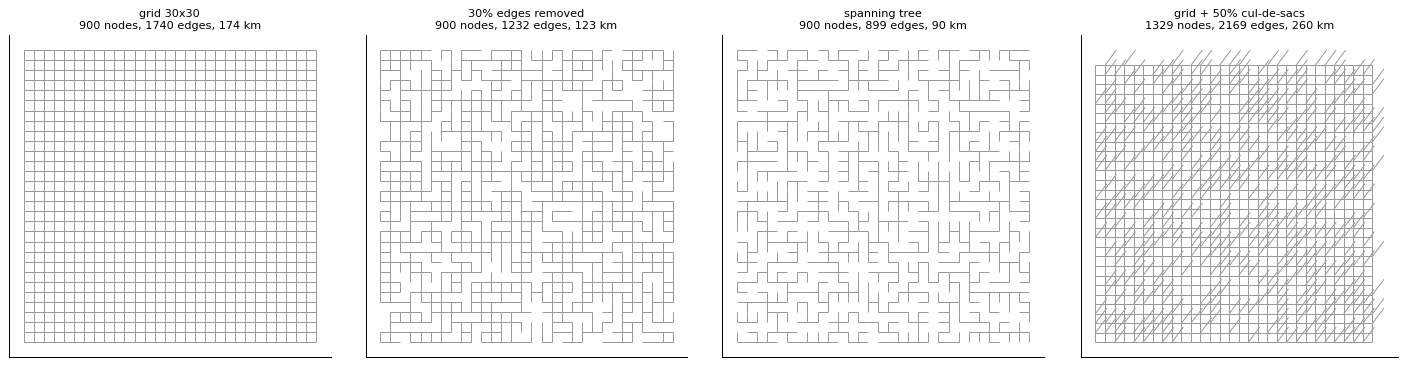

In [2]:
graphs_ = {
    "grid 30x30": GRID,
    "30% edges removed": g.drop_edges(GRID, 0.3),
    "spanning tree": g.tree(),
    "grid + 50% cul-de-sacs": g.grid_with_culdesacs(0.5),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, net) in zip(axes, graphs_.items()):
    draw(net, ax)
    ax.set_title(f"{name}\n{len(net.xy)} nodes, {len(net.u)} edges, {net.length.sum()/1000:.0f} km", fontsize=9)
plt.tight_layout()

## A2. One pair, edge by edge

Green = usable (`min(d_s(u)+w+d_t(v), d_s(v)+w+d_t(u)) <= B`). Grey = inside the ellipse but not usable. Pale = outside. Every green edge must lie inside the ellipse (U ⊆ A).

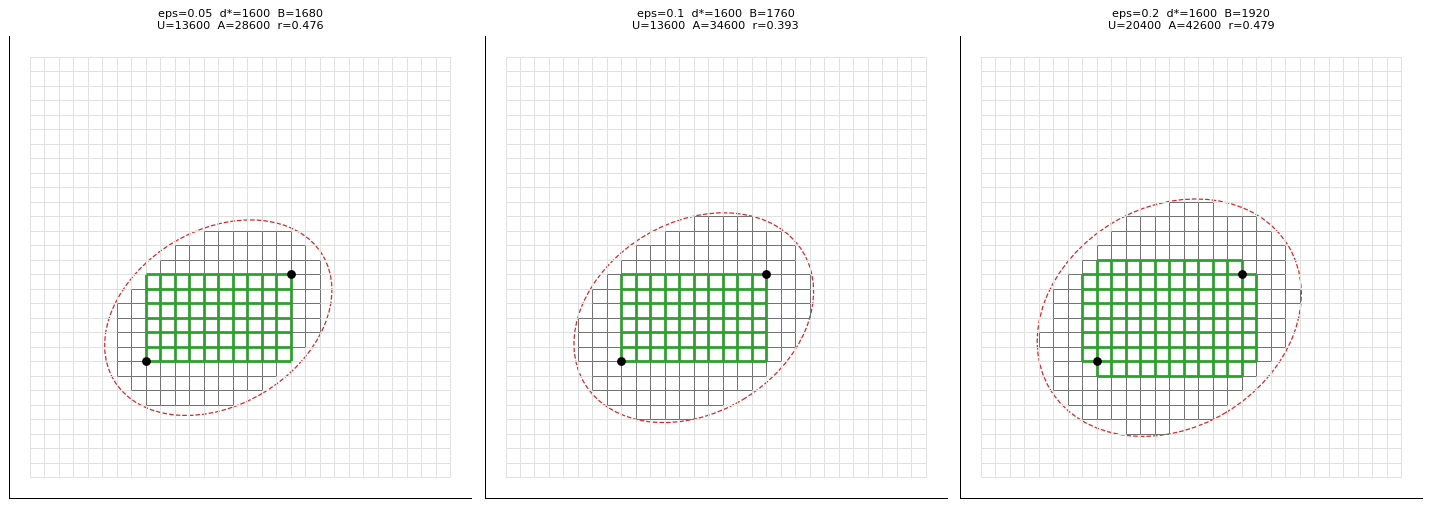

In [3]:
n = 30
s, t = 8 * n + 8, 18 * n + 14
d = dijkstra(GRID.csr, indices=[s, t])
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, eps in zip(axes, (0.05, 0.1, 0.2)):
    U, A, usable, edge_in = pair_score(GRID, d[0], d[1], s, t, eps)
    B = (1 + eps) * d[0][t]
    segs = np.stack([GRID.xy[GRID.u], GRID.xy[GRID.v]], axis=1)
    col = np.where(usable, "tab:green", np.where(edge_in, "0.45", "0.88"))
    ax.add_collection(LineCollection(segs, colors=col, linewidths=np.where(usable, 2.2, 0.8)))
    (sx, sy), (tx, ty) = GRID.xy[s], GRID.xy[t]
    c = np.hypot(tx - sx, ty - sy)
    ax.add_patch(Ellipse(((sx + tx) / 2, (sy + ty) / 2), B, np.sqrt(B**2 - c**2),
                         angle=np.degrees(np.arctan2(ty - sy, tx - sx)), fill=False, ec="tab:red", ls="--"))
    ax.plot(*GRID.xy[[s, t]].T, "ko")
    ax.autoscale(); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"eps={eps}  d*={d[0][t]:.0f}  B={B:.0f}\nU={U:.0f}  A={A:.0f}  r={U/A:.3f}", fontsize=9)
    assert not (usable & ~edge_in).any() and U <= A
plt.tight_layout()

## A3. Spur test: a spur of length w is usable iff 2w <= eps*d*  (d*=1000, slack=100)

In [4]:
for spur, expect in ((40.0, 1040.0), (60.0, 1000.0), (20.0, 5000.0)):
    net = g.path_with_spur(spur)
    d = dijkstra(net.csr, indices=[0, 10])
    U, A, usable, _ = pair_score(net, d[0], d[1], 0, 10, 0.1)
    print(f"spur {spur:>4} m: U={U:.0f} (expected {expect:.0f}), spur usable={usable[-1]}")
    # assert abs(U - expect) < 1e-6

spur 40.0 m: U=1040 (expected 1040), spur usable=True
spur 60.0 m: U=1000 (expected 1000), spur usable=False
spur 20.0 m: U=1020 (expected 5000), spur usable=True


## A4. Orderings

15:26:34 WARNING rfi.metric | bin dropped: too few pairs bin=2 n_pairs=6


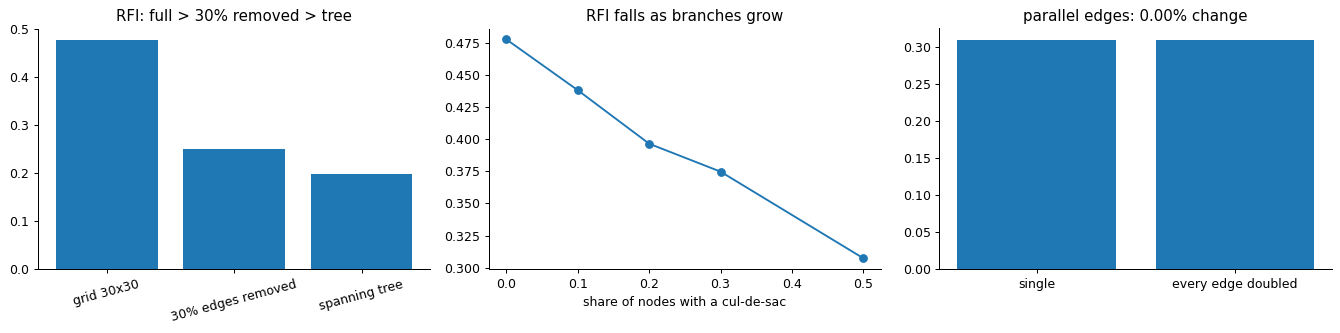

In [5]:
res = {name: score(net) for name, net in graphs_.items() if name != "grid + 50% cul-de-sacs"}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(list(res), [r["score"] for r in res.values()], color="tab:blue")
axes[0].set_title("RFI: full > 30% removed > tree"); axes[0].tick_params(axis="x", labelrotation=15)
assert res["grid 30x30"]["score"] > res["30% edges removed"]["score"] > res["spanning tree"]["score"]

shares = [0, 0.1, 0.2, 0.3, 0.5]
cul = [score(g.grid_with_culdesacs(sh))["score"] for sh in shares]
axes[1].plot(shares, cul, "o-"); axes[1].set_xlabel("share of nodes with a cul-de-sac")
axes[1].set_title("RFI falls as branches grow")
assert all(a > b for a, b in itertools.pairwise(cul))

base = g.drop_edges(GRID, 0.2)
a, b = score(base)["score"], score(g.duplicate_edges(base))["score"]
axes[2].bar(["single", "every edge doubled"], [a, b]); axes[2].set_title(f"parallel edges: {abs(a-b)/a:.2%} change")
assert abs(a - b) / a < 0.05
plt.tight_layout()

## A5. Per-bin statistics and exclusions

In [6]:
rows = []
for name, net in graphs_.items():
    r = score(net)
    for b, x in zip(r["bins"], r["diagnostics"]["bins"]):
        rows.append({"graph": name, "bin_m": b["range_m"], "n_pairs": b["n_pairs"], "used": b["used"],
                    "median_r": round(b["median_r"], 3), "iqr": round(b["iqr_r"], 3),
                     "circuity": round(b["median_circuity"], 3), "candidates": x["candidates"],
                     "unreachable": x["unreachable"], "too_circuitous": x["too_circuitous"]})
    rows[-1]["RFI"] = round(r["score"], 3)
pd.DataFrame(rows).set_index(["graph", "bin_m"])

15:26:36 WARNING rfi.metric | bin dropped: too few pairs bin=2 n_pairs=6


n_pairs   used  median_r    iqr  \
graph                  bin_m                                           
grid 30x30             (300, 750)        300   True     0.505  0.100   
                       (750, 1500)       300   True     0.407  0.113   
                       (1500, 3000)      300   True     0.520  0.148   
30% edges removed      (300, 750)        300   True     0.280  0.162   
                       (750, 1500)       300   True     0.184  0.105   
                       (1500, 3000)      300   True     0.287  0.096   
spanning tree          (300, 750)        122   True     0.265  0.135   
                       (750, 1500)        76   True     0.132  0.040   
                       (1500, 3000)        6  False     0.148  0.012   
grid + 50% cul-de-sacs (300, 750)        300   True     0.348  0.155   
                       (750, 1500)       300   True     0.251  0.123   
                       (1500, 3000)      300   True     0.323  0.118   

                                     circuity  candidates  unreachable  \
graph                  bin_m                                             
grid 30x30             (300, 750)       1.300        1458            0   
                       (750, 1500)      1.308        3629            0   
                       (1500, 3000)     1.303        5536            0   
30% edges removed      (300, 750)       1.372        1458           66   
                       (750, 1500)      1.381        3629          219   
                       (1500, 3000)     1.378        5536          623   
spanning tree          (300, 750)       1.387        1458            0   
                       (750, 1500)      1.412        3629            0   
                       (1500, 3000)     1.428        5536            0   
grid + 50% cul-de-sacs (300, 750)       1.265        1394            0   
                       (750, 1500)      1.309        3328            0   
                       (1500, 3000)     1.326        5757            0   

                                     too_circuitous    RFI  
graph                  bin_m                                
grid 30x30             (300, 750)                 0    NaN  
                       (750, 1500)                0    NaN  
                       (1500, 3000)               0  0.478  
30% edges removed      (300, 750)               542    NaN  
                       (750, 1500)              935    NaN  
                       (1500, 3000)             514  0.250  
spanning tree          (300, 750)              1336    NaN  
                       (750, 1500)             3553    NaN  
                       (1500, 3000)            5530  0.198  
grid + 50% cul-de-sacs (300, 750)               585    NaN  
                       (750, 1500)              886    NaN  
                       (1500, 3000)             738  0.307

## A6. Distribution of r per bin

15:26:37 WARNING rfi.metric | bin dropped: too few pairs bin=2 n_pairs=6


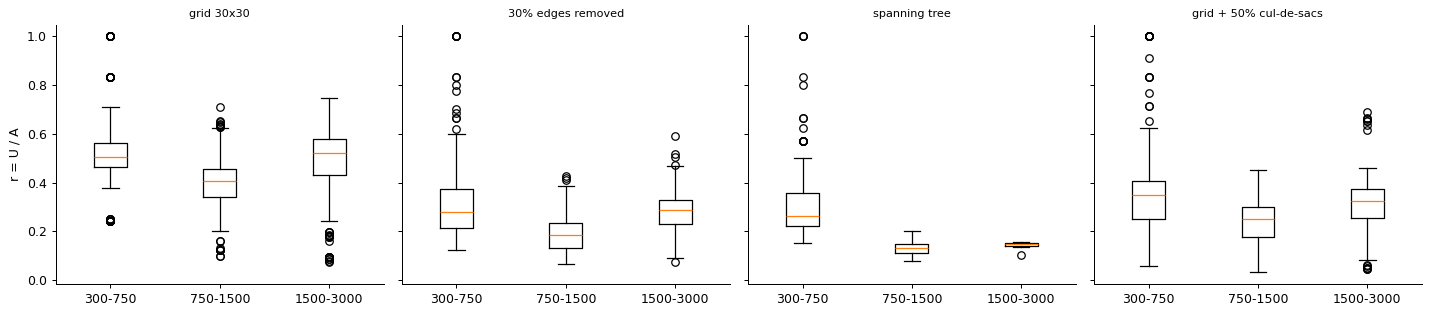

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (name, net) in zip(axes, graphs_.items()):
    p = score(net)["pairs"]
    ax.boxplot([p.loc[p["bin"] == b, "r"] for b in range(len(C.DIST_BINS))],
               tick_labels=[f"{lo}-{hi}" for lo, hi in C.DIST_BINS])
    ax.set_title(name, fontsize=9)
axes[0].set_ylabel("r = U / A")
plt.tight_layout()

## A7. Edge freedom map (share of in-ellipse trips that can use the edge)

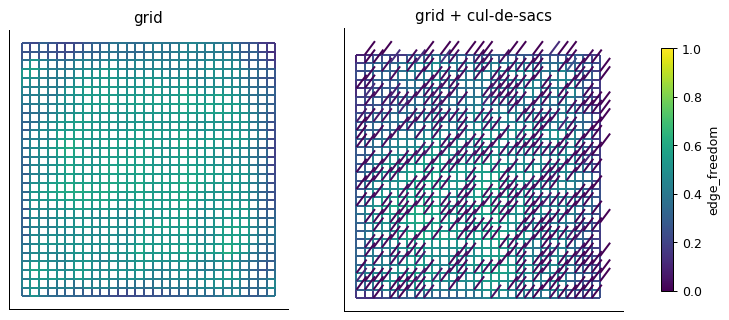

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, net, title in zip(axes, (GRID, graphs_["grid + 50% cul-de-sacs"]), ("grid", "grid + cul-de-sacs")):
    lc = draw(net, ax, values=score(net)["edge_freedom"], lw=1.6)
    ax.set_title(title)
fig.colorbar(lc, ax=axes, shrink=0.7, label="edge_freedom")

## A8. Invariants (assert): r <= 1 + 1e-6 and U ⊆ A on irregular graphs

In [9]:
rng = np.random.default_rng(0)
worst = 0.0
for seed in range(10):
    net = g.jittered_grid(n=25, seed=seed)
    eps = (0.05, 0.1, 0.5)[seed % 3]
    r = score(net, eps=eps, seed=seed)
    assert r["diagnostics"]["r_gt_1"] == 0
    worst = max(worst, r["pairs"]["r"].max())
    for s_, t_ in rng.integers(0, len(net.xy), (20, 2)):
        d = dijkstra(net.csr, indices=[s_, t_])
        if s_ == t_ or not np.isfinite(d[0][t_]):
            continue
        _, _, usable, edge_in = pair_score(net, d[0], d[1], s_, t_, eps)
        assert not (usable & ~edge_in).any()
print(f"max r over 10 irregular graphs: {worst:.6f}")
assert worst <= 1 + C.R_TOL

max r over 10 irregular graphs: 1.000000


## A9. Stability: seeds and eps

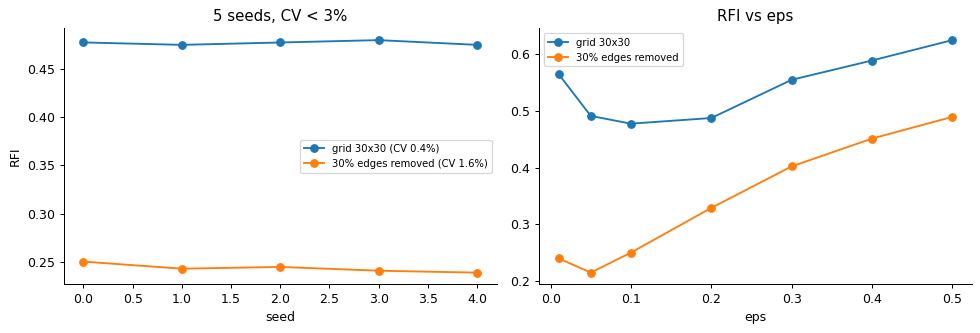

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name in ("grid 30x30", "30% edges removed"):
    net = graphs_[name]
    sc = np.array([score(net, seed=sd)["score"] for sd in range(5)])
    cv = sc.std() / sc.mean()
    axes[0].plot(range(5), sc, "o-", label=f"{name} (CV {cv:.1%})")
    assert cv < 0.03, (name, cv)
    lst = [0.01, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
    axes[1].plot(lst, [score(net, eps=e)["score"] for e in lst], "o-", label=name)
axes[0].set_xlabel("seed"); axes[0].set_ylabel("RFI"); axes[0].legend(fontsize=8); axes[0].set_title("5 seeds, CV < 3%")
axes[1].set_xlabel("eps"); axes[1].set_title("RFI vs eps"); axes[1].legend(fontsize=8)
plt.tight_layout()

## Part B (M5): real areas

Every real-data check below runs on **your polygons** in `polygons/*.geojson`, not on the ten
1.5 km circles listed in SPEC 3.3. The consequences are worth keeping in mind when reading the
numbers:

- Areas are **not equal in size** (2 to 23 km2) and not circles, so RFI differences between two
  places mix the street pattern with the shape and size of the polygon.
- Two polygons (`istanbul_beyoglu`, `istanbul_central`) are narrower than 3 km. They still fill
  all three trip bins here (their diagonals are longer than their widest side), but their long bin
  has fewer distinct origins to draw from. A bar is hatched if a bin was dropped.
- Some polygons overlap (e.g. `valencia_central` inside `valencia_central_big`), so the places are
  **not independent** observations.
- With only 9 places, a Spearman correlation has very little power. Treat the correlation table
  as a description of these nine places, not as a test.

Results are cached in `results/validation/` (set `RERUN = True` to recompute).

In [11]:
import warnings
import json
import logging

warnings.filterwarnings("ignore")
from scipy import stats

from rfi import baselines as bl
from rfi import rfi
from rfi.parser.area import parse_area
from rfi.result import Result

ROOT = Path.cwd().parent
C.CACHE_DIR = str(ROOT / "cache")  # the notebook runs from notebooks/; the cache is at the repo root
OUT = ROOT / "results" / "validation"
POLYGONS = {p.stem: p for p in sorted((ROOT / "polygons").glob("*.geojson"))}
RERUN = False
logging.getLogger().setLevel("WARNING")


def run(poly, eps=0.1, seed=0):
    """rfi() on a polygon file, cached on disk per (polygon, eps, seed, SNAP_M, DROP_SIDEWALKS)."""
    tag = f"{poly.stem}_e{eps}_s{seed}_snap{C.SNAP_M:g}_sw{int(C.DROP_SIDEWALKS)}"
    folder = OUT / tag
    if not RERUN and (folder / "result.json").exists():
        return Result.load(folder)
    res = rfi(str(poly), eps=eps, seed=seed)
    res.save(folder)
    return res


class override:
    """Temporarily set constants, e.g. `with override(SNAP_M=5): ...`."""

    def __init__(self, **kw):
        self.kw = kw

    def __enter__(self):
        self.old = {k: getattr(C, k) for k in self.kw}
        for k, v in self.kw.items():
            setattr(C, k, v)

    def __exit__(self, *exc):
        for k, v in self.old.items():
            setattr(C, k, v)


print(f"{len(POLYGONS)} polygons:", ", ".join(POLYGONS))

9 polygons: almaty_central, barcelona_central, istanbul_beyoglu, istanbul_central, moscow_central, moscow_north, spb_central, valencia_central, valencia_central_big


### B1. Score every polygon

`bins_used` < 3 means a bin had fewer than `MIN_PAIRS_PER_BIN` pairs and was dropped.

In [12]:
results = {name: run(p) for name, p in POLYGONS.items()}
rows = []
for name, res in results.items():
    used = [b for b in res.bins if b["used"]]
    rows.append({"place": name, "area_km2": res.meta["area_km2"], "RFI": res.score,
                 "bins_used": len(used), "circuity": res.circuity,
                 "nodes": res.meta["n_nodes"], "edges": res.meta["n_edges"],
                 **{f"r_bin{b['bin']}": b["median_r"] for b in res.bins},
                 "n_pairs": int(sum(b["n_pairs"] for b in res.bins)),
                 "boundary_drop": res.diagnostics["boundary"], "r_gt_1": res.diagnostics["r_gt_1"]})
places = pd.DataFrame(rows).set_index("place")
display(places.round(3))
assert (places["r_gt_1"] == 0).all(), "r > 1 somewhere: bug or snapping artefact"

# overlap between polygons (share of the smaller polygon covered by the other)
geoms = {n: parse_area(str(p)).polygon for n, p in POLYGONS.items()}
for a, b in itertools.combinations(geoms, 2):
    cover = geoms[a].intersection(geoms[b]).area / min(geoms[a].area, geoms[b].area)
    if cover > 0.05:
        print(f"overlap: {a} / {b}: {cover:.0%} of the smaller polygon")

,area_km2,RFI,bins_used,circuity,nodes,edges,r_bin0,r_bin1,r_bin2,n_pairs,boundary_drop,r_gt_1
place,,,,,,,,,,,,
almaty_central,7.471,0.256,3,1.310,19461,24958,0.203,0.249,0.317,900,299,0
barcelona_central,10.138,0.385,3,1.208,24091,31266,0.390,0.371,0.394,900,138,0
istanbul_beyoglu,2.326,0.294,3,1.229,4979,6771,0.244,0.283,0.355,900,0,0
istanbul_central,4.642,0.289,3,1.224,5676,7833,0.248,0.279,0.340,900,26,0
moscow_central,19.725,0.208,3,1.279,57898,71163,0.192,0.208,0.223,900,78,0
moscow_north,7.953,0.245,3,1.254,10384,14043,0.237,0.244,0.253,900,18,0
spb_central,23.017,0.213,3,1.281,57014,70858,0.196,0.202,0.240,900,115,0
valencia_central,6.162,0.308,3,1.212,20983,29265,0.271,0.301,0.353,900,12,0
valencia_central_big,21.445,0.292,3,1.224,37028,51513,0.279,0.268,0.329,900,17,0


15:26:45 WARNING rfi.parser.area | interior diameter is below the longest trip bin; long bins may stay empty diameter_m=2184 min_m=3000


15:26:45 WARNING rfi.parser.area | interior diameter is below the longest trip bin; long bins may stay empty diameter_m=2914 min_m=3000


overlap: valencia_central / valencia_central_big: 100% of the smaller polygon


### B2. Face validity: ranked RFI

Bars are the area score. Dots are the per-bin medians (short, medium, long trips). A hatched bar
would mean a dropped bin (none in this run).

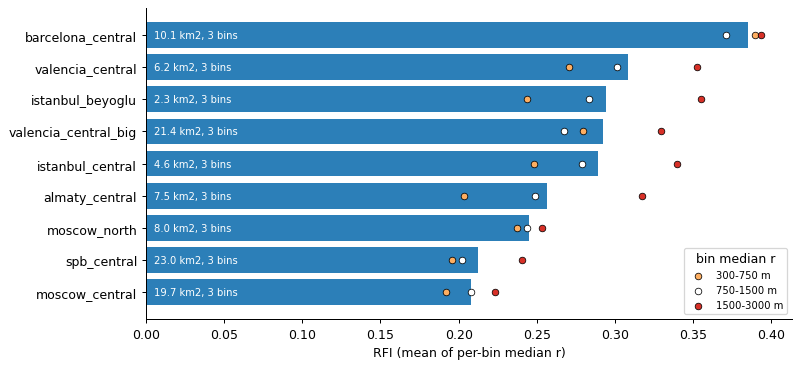

In [13]:
order = places.sort_values("RFI")
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(order.index, order["RFI"], color="#2c7fb8")
for bar, used in zip(bars, order["bins_used"]):
    if used < 3:
        bar.set_hatch("///"); bar.set_alpha(0.6)
for k, (c, label) in enumerate(zip(("#fdae61", "#ffffff", "#d73027"), ("300-750 m", "750-1500 m", "1500-3000 m"))):
    ax.scatter(order[f"r_bin{k}"], order.index, s=28, color=c, edgecolor="k", linewidth=0.6, zorder=3, label=label)
for y, (area, used) in enumerate(zip(order["area_km2"], order["bins_used"])):
    ax.text(0.005, y, f"{area:.1f} km2, {used} bins", va="center", color="white", fontsize=8)
ax.set_xlabel("RFI (mean of per-bin median r)"); ax.legend(title="bin median r", loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### B3. Stability on real data

Run on `valencia_central` (6 km2, 3.6 km across). Seeds change the sampled origins and pairs only;
the other knobs rebuild the network (or download a bigger buffer, for `eps`). The SPEC target is a
coefficient of variation below 3% over 5 seeds.

5 seeds: mean=0.3104 sd=0.0091 CV=2.93%  -> OK


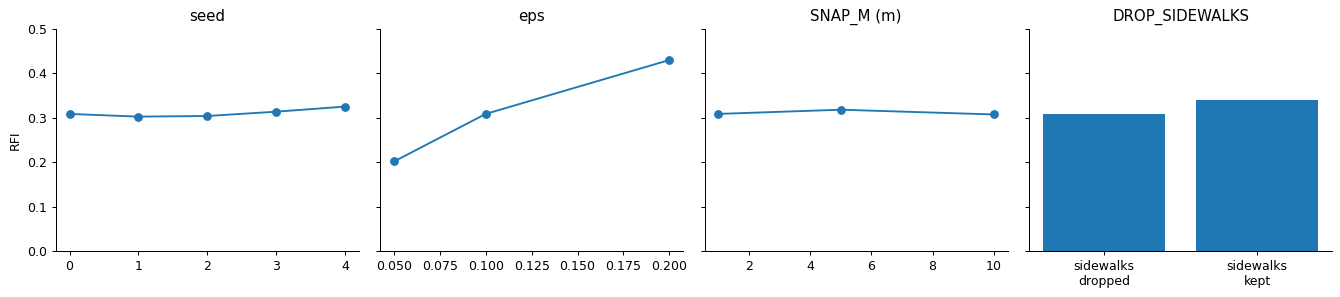

eps: {0.05: 0.2015, 0.1: 0.3083, 0.2: 0.4293}
SNAP_M: {1: 0.3083, 5: 0.3177, 10: 0.3071}
DROP_SIDEWALKS: {True: 0.3083, False: 0.3386}


In [14]:
base = POLYGONS["valencia_central"]
seed_scores = pd.Series({s: run(base, seed=s).score for s in range(5)}, name="RFI")
cv = seed_scores.std(ddof=1) / seed_scores.mean()
print(f"5 seeds: mean={seed_scores.mean():.4f} sd={seed_scores.std(ddof=1):.4f} CV={cv:.2%}"
      f"  -> {'OK' if cv < 0.03 else 'ABOVE 3% TARGET'}")

eps_scores = pd.Series({e: run(base, eps=e).score for e in (0.05, 0.1, 0.2)}, name="RFI")
snap_scores, sidewalk_scores = {}, {}
for snap in (1, 5, 10):
    with override(SNAP_M=snap):
        snap_scores[snap] = run(base).score
for flag in (True, False):
    with override(DROP_SIDEWALKS=flag):
        sidewalk_scores[flag] = run(base).score

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
axes[0].plot(seed_scores.index, seed_scores, "o-"); axes[0].set_title("seed"); axes[0].set_ylabel("RFI")
axes[1].plot(eps_scores.index, eps_scores, "o-"); axes[1].set_title("eps")
axes[2].plot(list(snap_scores), list(snap_scores.values()), "o-"); axes[2].set_title("SNAP_M (m)")
axes[3].bar(["sidewalks\ndropped", "sidewalks\nkept"], [sidewalk_scores[True], sidewalk_scores[False]]); axes[3].set_title("DROP_SIDEWALKS")
for ax in axes: ax.set_ylim(0, max(0.5, ax.get_ylim()[1]))
plt.tight_layout(); plt.show()
print("eps:", eps_scores.round(4).to_dict()); print("SNAP_M:", {k: round(v, 4) for k, v in snap_scores.items()})
print("DROP_SIDEWALKS:", {k: round(v, 4) for k, v in sidewalk_scores.items()})

### B4. Baselines (`rfi/baselines.py`)

Per place: intersection density, mean circuity (Boeing), orientation entropy (Boeing 2019),
link-node ratio, pedshed ratio at 400 and 800 m (Tal and Handy 2012), route directness, and
the bounded redundancy measures. Redundancy runs 100 short/medium pairs per place with a 10 000
path and 5 s limit per pair. **The exact Sevtsuk formula is not published**; these are our
reconstruction from the UNA tool description and Alkhaja et al. (2023). For a pair with shortest
distance d\* and budget B = (1+eps)·d\*, with P the simple s-t paths of length at most B:

- `RC = |P|`
- `RI_sum = sum of len(p) over P / d*`
- `RI_union = len(union of edges of P) / d*`

Pairs that hit a limit are `capped` (their counts are lower bounds). Capped share per place is
reported, and correlations below are computed with and without them.

In [15]:
def baselines_for(name, res):
    folder = OUT / f"{name}_e0.1_s0_snap1_sw1"
    f_row, f_pairs = folder / "baselines.json", folder / "redundancy.parquet"
    if not RERUN and f_row.exists() and f_pairs.exists():
        return json.loads(f_row.read_text()), pd.read_parquet(f_pairs)
    row, red = bl.all_baselines(res)
    f_row.write_text(json.dumps(row)); red.to_parquet(f_pairs)
    return row, red

base_rows, red_pairs = {}, {}
for name, res in results.items():
    base_rows[name], red_pairs[name] = baselines_for(name, res)
B = pd.DataFrame(base_rows).T
display(B.round(3))

,intersection_density,mean_circuity,orientation_entropy,link_node_ratio,pedshed_400,pedshed_800,route_directness,rc_median,ri_sum_median,ri_union_median,rc_median_uncapped,ri_union_median_uncapped,redundancy_capped_share
almaty_central,762.316,1.035,2.350,1.263,0.460,0.517,1.310,10000.0,10846.898,3.516,330.0,3.040,0.65
barcelona_central,522.569,1.013,3.036,1.317,0.461,0.493,1.208,10000.0,10904.036,3.676,451.0,3.600,0.73
istanbul_beyoglu,518.407,1.036,3.543,1.340,0.447,0.456,1.229,782.5,841.961,4.034,192.0,3.891,0.30
istanbul_central,481.429,1.040,3.515,1.375,0.442,0.464,1.224,1221.5,1323.991,4.872,112.0,4.277,0.35
moscow_central,929.270,1.063,3.574,1.209,0.454,0.486,1.279,10000.0,10880.675,3.070,168.0,2.754,0.63
moscow_north,512.891,1.060,3.344,1.358,0.416,0.405,1.254,1836.5,1989.963,3.955,263.0,3.661,0.37
spb_central,744.150,1.053,3.424,1.229,0.449,0.487,1.281,10000.0,10824.103,3.066,332.5,2.751,0.62
valencia_central,810.669,1.026,3.450,1.436,0.488,0.538,1.212,10000.0,10899.463,3.553,840.0,3.316,0.81
valencia_central_big,722.932,1.027,3.454,1.397,0.463,0.504,1.224,10000.0,10914.644,3.326,486.0,3.383,0.79


### B5. Novelty check: is RFI just intersection density?

Spearman correlation of RFI with each baseline, and the partial Spearman correlation after
removing intersection density (rank-transform both, regress out the density ranks, correlate
the residuals). The claim "RFI adds something beyond intersection density" holds only if the
partial correlations of RFI with the other baselines are not simply driven by density, and
RFI itself is not almost a monotone function of density. Reported either way.

In [16]:
def partial_spearman(x, y, z):
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))
    res_x = rx - np.polyval(np.polyfit(rz, rx, 1), rz)
    res_y = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    return stats.pearsonr(res_x, res_y)[0]

rfi_s = places["RFI"]
dens = B["intersection_density"]
rows = []
for col in B.columns:
    if col == "redundancy_capped_share":
        continue
    ok = B[col].notna()
    rho, p = stats.spearmanr(rfi_s[ok], B.loc[ok, col])
    part = partial_spearman(rfi_s[ok], B.loc[ok, col], dens[ok]) if col != "intersection_density" else np.nan
    part_d = partial_spearman(rfi_s[ok], B.loc[ok, col], B.loc[ok, "route_directness"]) if col != "route_directness" else np.nan
    rows.append({"baseline": col, "n": int(ok.sum()), "spearman_rho": rho, "p": p,
                 "partial_rho | density": part, "partial_rho | route_directness": part_d})
corr = pd.DataFrame(rows).set_index("baseline")
display(corr.round(3))
rho_d = corr.loc["intersection_density", "spearman_rho"]
print(f"RFI vs intersection density: rho = {rho_d:.2f} (rho^2 = {rho_d**2:.2f} of rank variance explained by density alone)")

,n,spearman_rho,p,partial_rho | density,partial_rho | route_directness
baseline,,,,,
intersection_density,9,-0.233,0.546,NaN,0.046
mean_circuity,9,-0.900,0.001,-0.934,-0.857
orientation_entropy,9,-0.167,0.668,-0.163,-0.432
link_node_ratio,9,0.600,0.088,0.569,0.158
pedshed_400,9,0.483,0.187,0.859,0.388
pedshed_800,9,0.350,0.356,0.679,0.422
route_directness,9,-0.817,0.007,-0.805,NaN
rc_median,9,-0.079,0.839,0.171,0.017
ri_sum_median,9,0.283,0.460,0.496,0.045


RFI vs intersection density: rho = -0.23 (rho^2 = 0.05 of rank variance explained by density alone)


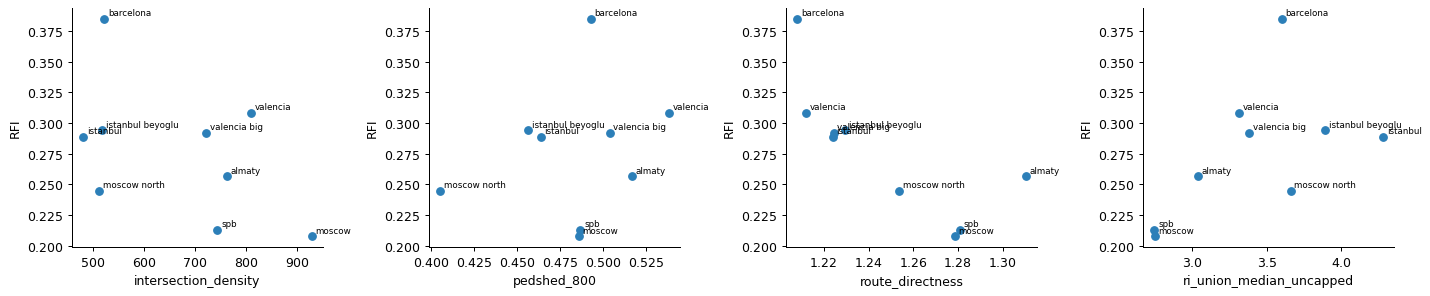

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col in zip(axes, ("intersection_density", "pedshed_800", "route_directness", "ri_union_median_uncapped")):
    ax.scatter(B[col], rfi_s, color="#2c7fb8")
    for name in B.index:
        ax.annotate(name.replace("_central", "").replace("_", " "), (B.loc[name, col], rfi_s[name]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel(col); ax.set_ylabel("RFI")
plt.tight_layout(); plt.show()

### B6. Redundancy: capped pairs, and how `RI_union·d*` relates to RFI's `U`

`RI_union·d*` is the length of the edges lying on some simple path within budget. RFI's `U` is the
length of edges lying on some walk within budget, simple or not, so `RI_union·d* <= U`, and the two
should be strongly correlated. The difference between the measures should then come from the
denominator: RFI divides `U` by the ellipse street length `A`, RI divides by `d*`. Only uncapped
pairs enter the comparison, because a capped count is a lower bound.

share of pairs that hit the 10k-path or 5 s limit:


,almaty_central,barcelona_central,istanbul_beyoglu,istanbul_central,moscow_central,moscow_north,spb_central,valencia_central,valencia_central_big
capped_share,0.65,0.73,0.3,0.35,0.63,0.37,0.62,0.81,0.79


375 uncapped pairs of 900
union_len vs U: Spearman = 0.991, Pearson = 0.995
union_len <= U for 100.0% of pairs
RI_union vs r = U/A (Spearman): 0.563


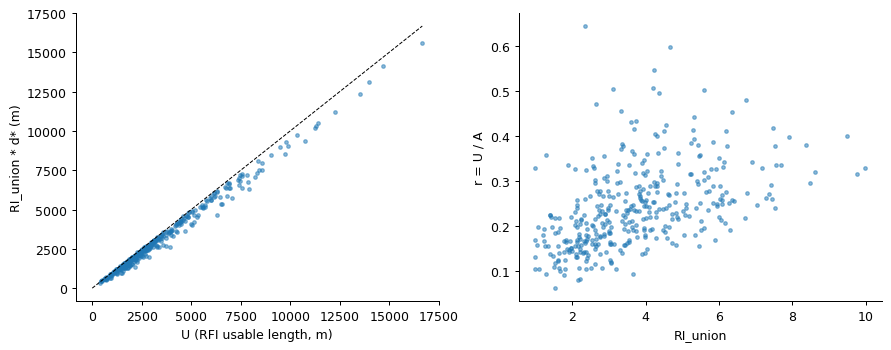

rc_median: Spearman with RFI, all pairs = -0.08; uncapped only = 0.50 (n=9)
ri_union_median: Spearman with RFI, all pairs = 0.48; uncapped only = 0.48 (n=9)


In [18]:
cap = pd.Series({n: r["capped"].mean() for n, r in red_pairs.items()}, name="capped_share")
print("share of pairs that hit the 10k-path or 5 s limit:"); display(cap.round(2).to_frame().T)

pooled = pd.concat([r.assign(place=n) for n, r in red_pairs.items()])
unc = pooled[~pooled["capped"]]
print(f"{len(unc)} uncapped pairs of {len(pooled)}")
if len(unc) > 2:
    print(f"union_len vs U: Spearman = {stats.spearmanr(unc['union_len'], unc['U'])[0]:.3f}, "
          f"Pearson = {stats.pearsonr(unc['union_len'], unc['U'])[0]:.3f}")
    print(f"union_len <= U for {(unc['union_len'] <= unc['U'] + 1e-6).mean():.1%} of pairs")
    print(f"RI_union vs r = U/A (Spearman): {stats.spearmanr(unc['ri_union'], unc['r'])[0]:.3f}")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].scatter(unc["U"], unc["union_len"], s=8, alpha=0.5); m = unc["U"].max()
    axes[0].plot([0, m], [0, m], "k--", lw=0.8); axes[0].set_xlabel("U (RFI usable length, m)"); axes[0].set_ylabel("RI_union * d* (m)")
    axes[1].scatter(unc["ri_union"], unc["r"], s=8, alpha=0.5); axes[1].set_xlabel("RI_union"); axes[1].set_ylabel("r = U / A")
    plt.tight_layout(); plt.show()

# area level: baselines with capped pairs included vs. excluded
for col, col_unc in (("rc_median", "rc_median_uncapped"), ("ri_union_median", "ri_union_median_uncapped")):
    ok = B[col_unc].notna()
    print(f"{col}: Spearman with RFI, all pairs = {stats.spearmanr(rfi_s, B[col])[0]:.2f}; "
          f"uncapped only = {stats.spearmanr(rfi_s[ok], B.loc[ok, col_unc])[0]:.2f} (n={int(ok.sum())})")

### Findings (this run)

- **Scores.** RFI ranges from 0.21 (`moscow_central`, `spb_central`) to 0.39 (`barcelona_central`);
  `valencia_central` is 0.31. All places fill all three bins and have `r > 1` nowhere.
- **Seeds.** CV over 5 seeds is 2.9%: under the 3% target, with little margin.
- **eps** moves the score strongly and monotonically (0.20, 0.31, 0.43 for 0.05, 0.1, 0.2), as it
  should, so RFI values are comparable only at the same eps. `SNAP_M` changes it by about 3%.
  `DROP_SIDEWALKS=False` raises it by about 10% (0.308 to 0.339), so that setting must be fixed too.
- **Boundary.** `almaty_central` loses 299 of its candidate pairs to the boundary check and
  `barcelona_central` 138. The README warns that this biases RFI upward for those places.
- **Novelty.** RFI is **not explained by intersection density**: rho = -0.23 (p = 0.55). It is,
  however, strongly negatively related to circuity: rho = -0.90 with mean circuity (p = 0.001) and
  -0.82 with route directness (p = 0.007), and the relation survives controlling for density. With
  nine places we cannot tell whether RFI adds anything beyond circuity. That needs more places
  (and independent ones) before claiming it.
- **Redundancy.** 30-81% of pairs hit the path or time limit, so `RC` is mostly a lower bound.
  `RI_union * d*` and RFI's `U` agree almost perfectly on uncapped pairs (Spearman 0.99, and
  `RI_union * d* <= U` always, as it must), while `RI_union` and `r = U / A` agree much less
  (0.56). So the denominator `A` is what separates the two.
- **Caveats.** Nine non-independent places of different sizes; correlations describe these places
  only.